In [ ]:

# Build and Train a Feedforward Neural Network
# o Use PyTorch or TensorFlow to build an MLP.
# o Train on Fashion-MNIST dataset.
# o Tune hidden layers and activation functions.
# o Report accuracy and loss curves.

In [ ]:
# Load Libraries
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

I0000 00:00:1794490889.169716    4857 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794490893.328406    4857 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794490903.326444    4857 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [ ]:
# Load and preprocess Fashion-MNIST CSV
train = pd.read_csv("dataset/Fashion/fashion-mnist_train.csv")
test = pd.read_csv("dataset/Fashion/fashion-mnist_test.csv")

x_train = train.iloc[:, 1:].values.astype('float32') / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values.astype('float32') / 255.0
y_test = test.iloc[:, 0].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


In [ ]:
# Build and Train the 2 MLP Models
histories = []
results = []

configs = [(1, 'relu'), (2, 'tanh')]

for layers, activation in configs:
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(784,)))

    for i in range(layers):
        model.add(tf.keras.layers.Dense(128, activation=activation))

    model.add(tf.keras.layers.Dense(10, activation='softmax'))

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    history = model.fit(x_train, y_train, epochs=5,
                        batch_size=64, validation_split=0.1)

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    print("Hidden layers:", layers, "Activation:", activation)
    print("Test accuracy:", accuracy * 100, "%")

    histories.append(history)
    results.append(accuracy)

E0000 00:00:1794490940.899187    4857 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/5


W0000 00:00:1794490941.632470    4857 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 22s 24ms/step - accuracy: 0.8164 - loss: 0.5299 - val_accuracy: 0.8508 - val_loss: 0.4271
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 24ms/step - accuracy: 0.8605 - loss: 0.3962 - val_accuracy: 0.8648 - val_loss: 0.3885
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.8728 - loss: 0.3588 - val_accuracy: 0.8703 - val_loss: 0.3647
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.8818 - loss: 0.3317 - val_accuracy: 0.8752 - val_loss: 0.3538
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.8851 - loss: 0.3159 - val_accuracy: 0.8820 - val_loss: 0.3357
Hidden layers: 1 Activation: relu
Test accuracy: 88.30999732017517 %
Epoch 1/5


W0000 00:00:1794491068.927717    4857 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 23s 26ms/step - accuracy: 0.8199 - loss: 0.4971 - val_accuracy: 0.8515 - val_loss: 0.4145
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 22s 26ms/step - accuracy: 0.8641 - loss: 0.3735 - val_accuracy: 0.8640 - val_loss: 0.3747
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 22s 26ms/step - accuracy: 0.8752 - loss: 0.3396 - val_accuracy: 0.8770 - val_loss: 0.3462
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 22s 26ms/step - accuracy: 0.8839 - loss: 0.3147 - val_accuracy: 0.8647 - val_loss: 0.3579
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 22s 26ms/step - accuracy: 0.8900 - loss: 0.2952 - val_accuracy: 0.8843 - val_loss: 0.3206
Hidden layers: 2 Activation: tanh
Test accuracy: 88.12999725341797 %


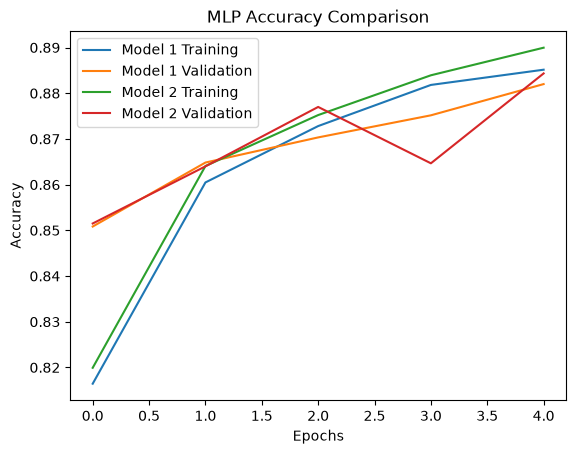

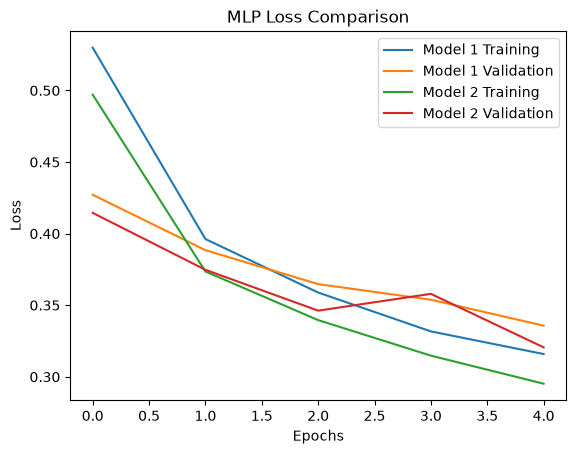

Model 1 Accuracy: 88.30999732017517 %
Model 2 Accuracy: 88.12999725341797 %
Best Model: Model 1


In [ ]:
# Plot curves
for i, h in enumerate(histories):
    plt.plot(h.history['accuracy'], label=f'Model {i+1} Training')
    plt.plot(h.history['val_accuracy'], label=f'Model {i+1} Validation')

plt.title("MLP Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

for i, h in enumerate(histories):
    plt.plot(h.history['loss'], label=f'Model {i+1} Training')
    plt.plot(h.history['val_loss'], label=f'Model {i+1} Validation')

plt.title("MLP Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

print("Model 1 Accuracy:", results[0] * 100, "%")
print("Model 2 Accuracy:", results[1] * 100, "%")
print("Best Model:", "Model 1" if results[0] > results[1] else "Model 2")